# 06 — Phase 6 · Explainability and error analysis

## Question
Which flow features drive the decisions, and what do false positives and false
negatives look like to an analyst?

## Method
- `permutation_importance` on the **test fold**, never the train fold.
- One diagnostic run for Experiment 1 (13-class random forest) and one for
  Experiment 2 (three held-out families: best, median and worst from the LOADO
  results).
- Models are refitted here on a 10,000-rows-per-class training cap so the
  notebook stays executable; the headline scores remain those of the full-data
  experiments.
- FP/FN galleries show real flow values for misclassified rows.
- SHAP is optional in the plan.  It is not installed on Python 3.14 here;
  permutation importance already satisfies the interpretation requirement.

Every claim is tagged **Observation**, **Interprétation ML**,
**Interprétation cyber** or **Limite**.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance

from daf_projet.data import BENIGN, build_pipeline, group_attack_families, purge_family, split, subsample
from daf_projet.experiments.common import load_deduped
from daf_projet.metrics import confusion_matrix, evaluate

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120

ROOT = Path.cwd()
if not (ROOT / "dataset").exists():
    ROOT = ROOT.parent
RES = ROOT / "results"
FIG = ROOT / "figures"

X, y_family, y_binary, meta = load_deduped()
X_train, X_test, y_family_train, y_family_test = split(X, y_family, seed=42)
print(X.shape, X_train.shape, X_test.shape)

GALLERY_COLUMNS = [
    "Protocol",
    "Flow Duration",
    "Flow Bytes/s",
    "Flow Packets/s",
    "Packet Length Mean",
    "Fwd Packet Length Mean",
    "Bwd Packet Length Mean",
    "SYN Flag Count",
    "ACK Flag Count",
    "Init Fwd Win Bytes",
]

(418884, 77) (335107, 77) (83777, 77)


,feature,importance_mean,importance_std
0,Bwd Header Length,0.0178,0.0001
1,Init Fwd Win Bytes,0.0165,0.0052
2,Init Bwd Win Bytes,0.0155,0.0004
3,Flow Bytes/s,0.0116,0.0008
4,Fwd Seg Size Min,0.0093,0.0006
5,Fwd Packet Length Min,0.0010,0.0050
6,Flow IAT Std,0.0010,0.0037
7,Fwd IAT Std,0.0005,0.0008
8,Fwd IAT Total,0.0004,0.0009
9,ACK Flag Count,0.0003,0.0000


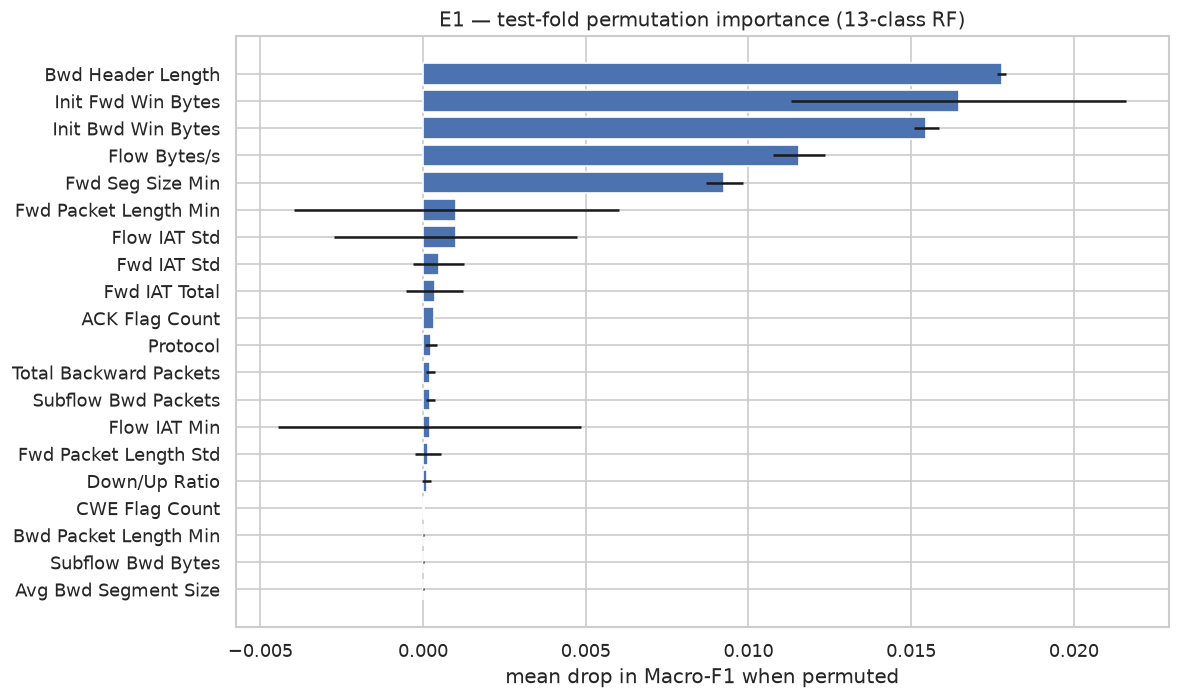

In [2]:
# E1 diagnostic model: 13-class random forest on a capped training fold.
y_train = group_attack_families(y_family_train)
y_test = group_attack_families(y_family_test)
X_train_cap, y_train_cap = subsample(X_train, y_train, cap=10_000, seed=42)

e1 = build_pipeline(
    RandomForestClassifier(n_estimators=300, class_weight="balanced", n_jobs=-1, random_state=42)
)
e1.fit(X_train_cap, y_train_cap)

# Stratified test sample for permutation importance.
sample_parts = []
for _, group in X_test.assign(_y=y_test).groupby("_y", sort=False):
    sample_parts.append(group.sample(n=min(250, len(group)), random_state=42))
perm_sample = pd.concat(sample_parts).drop(columns="_y")
y_perm = y_test.loc[perm_sample.index]

perm = permutation_importance(
    e1,
    perm_sample,
    y_perm,
    scoring="f1_macro",
    n_repeats=3,
    random_state=42,
    n_jobs=1,
)
e1_perm = (
    pd.DataFrame(
        {
            "feature": perm_sample.columns,
            "importance_mean": perm.importances_mean,
            "importance_std": perm.importances_std,
        }
    )
    .sort_values("importance_mean", ascending=False)
    .reset_index(drop=True)
)
e1_perm.to_csv(RES / "xai_permutation_e1.csv", index=False)
display(e1_perm.head(20).round(4))

fig, ax = plt.subplots(figsize=(10, 6))
top = e1_perm.head(20).sort_values("importance_mean")
ax.barh(top["feature"], top["importance_mean"], xerr=top["importance_std"], color="#4c72b0")
ax.set_xlabel("mean drop in Macro-F1 when permuted")
ax.set_title("E1 — test-fold permutation importance (13-class RF)")
fig.tight_layout()
fig.savefig(FIG / "06_xai_permutation_e1.png", bbox_inches="tight")
plt.show()

E2 families (best, median, worst): ['DrDoS_SNMP', 'TFTP', 'Syn']


,family,feature,importance_mean,importance_std
48,DrDoS_SNMP,URG Flag Count,0.0020,0.0000
65,DrDoS_SNMP,Init Fwd Win Bytes,0.0010,0.0010
0,DrDoS_SNMP,Protocol,0.0000,0.0000
5,DrDoS_SNMP,Bwd Packets Length Total,0.0000,0.0000
7,DrDoS_SNMP,Fwd Packet Length Min,0.0000,0.0000
9,DrDoS_SNMP,Fwd Packet Length Std,0.0000,0.0000
10,DrDoS_SNMP,Bwd Packet Length Max,0.0000,0.0000
11,DrDoS_SNMP,Bwd Packet Length Min,0.0000,0.0000
12,DrDoS_SNMP,Bwd Packet Length Mean,0.0000,0.0000
13,DrDoS_SNMP,Bwd Packet Length Std,0.0000,0.0000


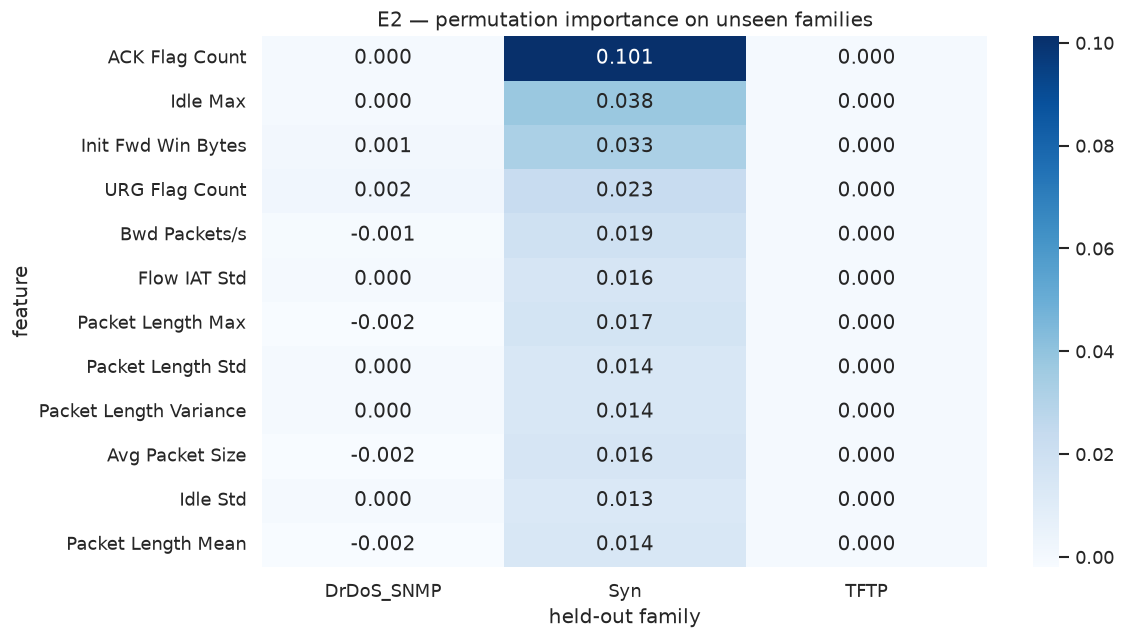

In [3]:
def balanced_eval(family, cap=10_000, seed=42):
    X_pool, y_pool, held_X, held_y = purge_family(X, y_family, family)
    X_tr, X_te, y_tr, y_te = split(X_pool, y_pool, seed=seed)
    X_tr, y_tr = subsample(X_tr, y_tr, cap=cap, seed=seed)
    benign_idx = y_te.index[y_te == BENIGN].to_numpy()
    n = min(len(held_X), len(benign_idx))
    rng = np.random.default_rng(seed)
    held_pos = rng.choice(len(held_X), size=n, replace=False) if len(held_X) > n else np.arange(len(held_X))
    ben_pos = rng.choice(benign_idx, size=n, replace=False) if len(benign_idx) > n else benign_idx
    X_attack = held_X.iloc[held_pos].reset_index(drop=True).copy()
    X_benign = X_te.loc[ben_pos].reset_index(drop=True).copy()
    X_attack.attrs = {}
    X_benign.attrs = {}
    X_eval = pd.concat([X_attack, X_benign], ignore_index=True)
    y_eval = np.r_[np.ones(len(X_attack), dtype=np.int8), np.zeros(len(X_benign), dtype=np.int8)]
    return X_tr, (y_tr != BENIGN).astype("int8"), X_eval, y_eval, X_attack

# Pick best / median / worst held-out family for the RF from exp2.
exp2 = pd.read_csv(RES / "exp2.csv")
rf = exp2[exp2["model"] == "random_forest"].groupby("family")["recall_family"].mean().sort_values()
chosen = [rf.index[-1], rf.index[len(rf) // 2], rf.index[0]]
print("E2 families (best, median, worst):", chosen)

perm_rows = []
for family in chosen:
    X_tr, y_tr, X_eval, y_eval, _ = balanced_eval(family)
    model = build_pipeline(
        RandomForestClassifier(n_estimators=300, class_weight="balanced", n_jobs=-1, random_state=42)
    )
    model.fit(X_tr, y_tr)
    n = min(500, len(X_eval))
    idx = np.random.default_rng(42).choice(len(X_eval), size=n, replace=False)
    perm = permutation_importance(
        model,
        X_eval.iloc[idx],
        y_eval[idx],
        scoring="f1_macro",
        n_repeats=2,
        random_state=42,
        n_jobs=1,
    )
    part = pd.DataFrame(
        {
            "family": family,
            "feature": X_eval.columns,
            "importance_mean": perm.importances_mean,
            "importance_std": perm.importances_std,
        }
    )
    perm_rows.append(part)

e2_perm = pd.concat(perm_rows, ignore_index=True)
e2_perm.to_csv(RES / "xai_permutation_e2.csv", index=False)
display(e2_perm.sort_values(["family", "importance_mean"], ascending=[True, False]).groupby("family").head(10).round(4))

fig, ax = plt.subplots(figsize=(10, 5.5))
top_features = e2_perm.groupby("feature")["importance_mean"].mean().nlargest(12).index
heat = e2_perm[e2_perm["feature"].isin(top_features)].pivot(index="feature", columns="family", values="importance_mean")
sns.heatmap(heat.loc[top_features], annot=True, fmt=".3f", cmap="Blues", ax=ax)
ax.set_title("E2 — permutation importance on unseen families")
ax.set_xlabel("held-out family")
fig.tight_layout()
fig.savefig(FIG / "06_xai_permutation_e2.png", bbox_inches="tight")
plt.show()

In [4]:
# FP/FN gallery for the E1 binary task.
y_bin_train = (y_family_train != BENIGN).astype("int8")
y_bin_test = (y_family_test != BENIGN).astype("int8")
X_bin_train, y_bin_train_cap = subsample(X_train, y_bin_train, cap=10_000, seed=42)
binary_model = build_pipeline(
    RandomForestClassifier(n_estimators=300, class_weight="balanced", n_jobs=-1, random_state=42)
)
binary_model.fit(X_bin_train, y_bin_train_cap)
pred = binary_model.predict(X_test)
proba = binary_model.predict_proba(X_test)[:, 1]
report = X_test.loc[:, GALLERY_COLUMNS].copy()
report.insert(0, "true", y_bin_test.map({0: "Benign", 1: "DDoS"}).to_numpy())
report.insert(1, "predicted", pd.Series(pred, index=report.index).map({0: "Benign", 1: "DDoS"}))
report.insert(2, "p_DDoS", proba)
fp_all = report[(report["true"] == "Benign") & (report["predicted"] == "DDoS")]
fn_all = report[(report["true"] == "DDoS") & (report["predicted"] == "Benign")]
fp = fp_all.nlargest(10, "p_DDoS")
fn = fn_all.nsmallest(10, "p_DDoS")
print(f"FP={len(fp_all):,}  FN={len(fn_all):,} on {len(report):,} test rows")
print("False positives (Benign flagged as DDoS):")
display(fp)
print("False negatives (DDoS missed):")
display(fn)
pd.concat([fp.assign(gallery="FP"), fn.assign(gallery="FN")]).to_csv(RES / "xai_fp_fn_e1.csv", index=False)

FP=7  FN=165 on 83,777 test rows
False positives (Benign flagged as DDoS):


,true,predicted,p_DDoS,Protocol,Flow Duration,Flow Bytes/s,Flow Packets/s,Packet Length Mean,Fwd Packet Length Mean,Bwd Packet Length Mean,SYN Flag Count,ACK Flag Count,Init Fwd Win Bytes
163702,Benign,DDoS,0.687000,17.0,2.0,50000000.0,1000000.000000,50.0,50.0,0.0,0.0,0.0,-1.0
28829,Benign,DDoS,0.583333,6.0,8192004.0,0.0,0.488281,0.0,0.0,0.0,0.0,1.0,29200.0
14496,Benign,DDoS,0.534111,17.0,2.0,38000000.0,1000000.000000,38.0,38.0,0.0,0.0,0.0,-1.0
163777,Benign,DDoS,0.510389,17.0,41.0,2000000.0,48780.487805,41.0,41.0,0.0,0.0,0.0,-1.0
11527,Benign,DDoS,0.506667,6.0,322729.0,0.0,9.295725,0.0,0.0,0.0,0.0,0.0,613.0
13266,Benign,DDoS,0.503333,6.0,48.0,0.0,41666.666667,0.0,0.0,0.0,0.0,0.0,235.0
306971,Benign,DDoS,0.503333,6.0,48.0,0.0,41666.666667,0.0,0.0,0.0,0.0,0.0,238.0


False negatives (DDoS missed):


,true,predicted,p_DDoS,Protocol,Flow Duration,Flow Bytes/s,Flow Packets/s,Packet Length Mean,Fwd Packet Length Mean,Bwd Packet Length Mean,SYN Flag Count,ACK Flag Count,Init Fwd Win Bytes
276042,DDoS,Benign,0.003333,6.0,2.0,0.000000e+00,1000000.000000,0.000000,0.000000,0.000000,0.0,0.0,243.0
168803,DDoS,Benign,0.003333,6.0,1447.0,3.593642e+04,1382.170007,34.666668,52.000000,0.000000,0.0,0.0,259.0
125684,DDoS,Benign,0.010000,6.0,93.0,0.000000e+00,53763.440860,0.000000,0.000000,0.000000,0.0,0.0,259.0
2731,DDoS,Benign,0.013333,17.0,3.0,1.733333e+07,666666.666667,26.000000,26.000000,0.000000,0.0,0.0,-1.0
198029,DDoS,Benign,0.013333,6.0,158.0,1.518987e+05,31645.569620,4.000000,0.000000,6.000000,0.0,0.0,145.0
181104,DDoS,Benign,0.020000,6.0,1494846.0,2.943447e+02,7.358618,36.666668,14.857142,84.000000,0.0,0.0,145.0
195264,DDoS,Benign,0.020000,6.0,175.0,1.371429e+05,28571.428571,4.000000,0.000000,6.000000,0.0,0.0,145.0
109772,DDoS,Benign,0.020000,6.0,2089379.0,2.873581e+03,20.101667,139.627914,67.699997,211.363632,0.0,0.0,229.0
110604,DDoS,Benign,0.020000,6.0,1285507.0,5.289742e+02,15.558064,32.380951,44.000000,24.000000,0.0,0.0,259.0
81548,DDoS,Benign,0.023333,6.0,70661.0,0.000000e+00,42.456235,0.000000,0.000000,0.000000,0.0,0.0,235.0


In [5]:
# FP/FN gallery for one unseen family (the worst from exp2).
family = chosen[-1]
X_tr, y_tr, X_eval, y_eval, X_attack = balanced_eval(family)
model = build_pipeline(
    RandomForestClassifier(n_estimators=300, class_weight="balanced", n_jobs=-1, random_state=42)
)
model.fit(X_tr, y_tr)
pred = model.predict(X_eval)
proba = model.predict_proba(X_eval)[:, 1]
report = X_eval.loc[:, GALLERY_COLUMNS].copy()
report.insert(0, "true", pd.Series(y_eval).map({0: "Benign", 1: family}))
report.insert(1, "predicted", pd.Series(pred).map({0: "Benign", 1: "DDoS"}))
report.insert(2, "p_DDoS", proba)
print(f"held-out family: {family}")
print("Missed attacks (FN):")
display(report[(report['true'] == family) & (report['predicted'] == 'Benign')].nsmallest(10, 'p_DDoS'))
print("Benign false alarms (FP):")
display(report[(report['true'] == 'Benign') & (report['predicted'] == 'DDoS')].nlargest(10, 'p_DDoS'))
report.to_csv(RES / f"xai_fp_fn_e2_{family}.csv", index=False)

held-out family: Syn
Missed attacks (FN):


,true,predicted,p_DDoS,Protocol,Flow Duration,Flow Bytes/s,Flow Packets/s,Packet Length Mean,Fwd Packet Length Mean,Bwd Packet Length Mean,SYN Flag Count,ACK Flag Count,Init Fwd Win Bytes
3048,Syn,Benign,0.003333,6.0,884496.0,307.519763,10.175286,27.200001,14.857142,84.000000,0.0,0.0,128.0
8168,Syn,Benign,0.016667,6.0,52687.0,0.000000,94.900070,0.000000,0.000000,0.000000,0.0,0.0,259.0
15533,Syn,Benign,0.026667,6.0,144.0,166666.666667,34722.222222,4.000000,0.000000,6.000000,0.0,0.0,145.0
2377,Syn,Benign,0.046667,6.0,175.0,137142.857143,28571.428571,4.000000,0.000000,6.000000,0.0,0.0,145.0
15603,Syn,Benign,0.048136,6.0,593219.0,0.000000,3.371436,0.000000,0.000000,0.000000,0.0,0.0,247.0
5749,Syn,Benign,0.056667,6.0,10832483.0,35.818196,2.123244,16.166666,6.666667,23.428572,0.0,1.0,29200.0
37,Syn,Benign,0.058136,6.0,703898.0,0.000000,2.841321,0.000000,0.000000,0.000000,0.0,0.0,247.0
8803,Syn,Benign,0.096667,6.0,10992048.0,298.215583,0.909749,298.000000,442.000000,278.857147,0.0,0.0,229.0
12001,Syn,Benign,0.100008,6.0,131.0,0.000000,22900.763359,0.000000,0.000000,0.000000,0.0,0.0,259.0
10359,Syn,Benign,0.126667,6.0,4885.0,402865.916070,818.833163,448.000000,272.000000,565.333313,0.0,0.0,244.0


Benign false alarms (FP):


,true,predicted,p_DDoS,Protocol,Flow Duration,Flow Bytes/s,Flow Packets/s,Packet Length Mean,Fwd Packet Length Mean,Bwd Packet Length Mean,SYN Flag Count,ACK Flag Count,Init Fwd Win Bytes
22377,Benign,DDoS,0.996667,17.0,1.0,1.660000e+08,2.000000e+06,83.0,83.0,0.0,0.0,0.0,-1.0
30615,Benign,DDoS,0.994967,17.0,1.0,1.940000e+08,2.000000e+06,97.0,97.0,0.0,0.0,0.0,-1.0
35213,Benign,DDoS,0.992179,17.0,1.0,8.200000e+07,2.000000e+06,41.0,41.0,0.0,0.0,0.0,-1.0
23888,Benign,DDoS,0.987815,17.0,2.0,3.700000e+07,1.000000e+06,37.0,37.0,0.0,0.0,0.0,-1.0
28873,Benign,DDoS,0.957254,17.0,41.0,2.000000e+06,4.878049e+04,41.0,41.0,0.0,0.0,0.0,-1.0
36190,Benign,DDoS,0.942731,17.0,2.0,3.800000e+07,1.000000e+06,38.0,38.0,0.0,0.0,0.0,-1.0
35795,Benign,DDoS,0.936667,17.0,2.0,3.100000e+07,1.000000e+06,31.0,31.0,0.0,0.0,0.0,-1.0
37445,Benign,DDoS,0.934734,17.0,5.0,1.480000e+07,4.000000e+05,37.0,37.0,0.0,0.0,0.0,-1.0
27609,Benign,DDoS,0.909103,17.0,3.0,2.066667e+07,6.666667e+05,31.0,31.0,0.0,0.0,0.0,-1.0
26504,Benign,DDoS,0.893333,17.0,1.0,1.000000e+08,2.000000e+06,50.0,50.0,0.0,0.0,0.0,-1.0


## Findings

**Observation.** The top E1 permutation features are TCP header/window fields
(`Bwd Header Length`, `Init Fwd Win Bytes`, `Init Bwd Win Bytes`) and
`Flow Bytes/s`, not mean packet sizes or bulk-rate columns.  On E2, the
near-perfect families (`DrDoS_SNMP`, `TFTP`) have near-zero importance for every
single feature, so no one feature is critical; Syn is more fragile
(`ACK Flag Count`, `Idle Max`, `Init Fwd Win Bytes`).

**Interprétation ML.** The models are not using only `Protocol`; they combine
TCP header/window information with rate.  This explains both the binary success
and the multiclass confusion between families with similar header profiles.
Permutation importance on test confirms the signal is not a train-fold artefact.

**Interprétation cyber.** FP/FN galleries are what a SOC analyst actually
sees: a small number of benign flows with attack-like header/rate profiles, and
attacks whose rate is below the learned threshold.  The gallery argues for
threshold tuning and family-specific playbooks rather than a single global
cut-off.  A missed unseen family is more dangerous than a mislabelled known
family because no existing rule covers it.

**Limite.** Permutation importance is model- and test-sample-dependent, and
correlated features share credit.  The diagnostic models are capped at 10,000
rows per class, so their importances are indicative, not exact for the
full-data models.  SHAP was not installed on Python 3.14; no claim depends on
it.  The FP/FN galleries are samples, not a complete error taxonomy.